# Task 2 - Player Segment Classification (4 classes, metric: F1 macro)

CPE342 Karena Player Intelligence System

> **Rules followed:** models are trained from scratch (no pre-trained models, no AutoML); every statistic (clip bounds, imputer, scaler, category lists, thresholds, class weights) is computed from the **train** set only; the test set is used only for the final prediction.

## 1. Import Libraries & Configuration

In [1]:
import os, time, warnings, joblib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.feature_selection import f_classif
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report
warnings.filterwarnings("ignore")

SEED = 42
QUICK = os.environ.get("QUICK") == "1"   # QUICK=1 -> small smoke test (results not meaningful)
ROOT = Path.cwd()                         # repo root, or the task2/ folder itself
OUT = ROOT / ("outputs_quick" if QUICK else "outputs")
(OUT / "models").mkdir(parents=True, exist_ok=True)
print("QUICK mode:", QUICK)
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split, StratifiedKFold

TASK, TARGET, KIND = 2, "segment", "multi"
NAMES = ["Casual", "Grinder", "Social", "Whale"]
NOISE = ["random_metric_1", "random_metric_2", "random_metric_3"]   # datacard: pure noise
DATA = ROOT / "task2" if (ROOT / "task2" / "train.csv").exists() else ROOT   # run from repo root or from inside task2/

QUICK mode: False


In [2]:
# ---------- helper functions (all statistics are fitted on TRAIN only) ----------
def fit_clip(X, lo=0.001, hi=0.999):
    """Winsorisation bounds (0.1% / 99.9% quantiles) from train."""
    return {c: (X[c].quantile(lo), X[c].quantile(hi)) for c in X.select_dtypes("number").columns}

def apply_clip(X, bounds):
    X = X.copy()
    for c, (lo, hi) in bounds.items():
        if c in X:
            X[c] = X[c].clip(lo, hi)
    return X

def impute_scale(X, Xt):
    """Median-impute + standardise (for LogisticRegression / Ridge / RandomForest)."""
    imp, sc = SimpleImputer(strategy="median"), StandardScaler()
    Xi = pd.DataFrame(sc.fit_transform(imp.fit_transform(X)), columns=X.columns, index=X.index)
    Xti = pd.DataFrame(sc.transform(imp.transform(Xt)), columns=X.columns, index=Xt.index)
    return Xi, Xti, (imp, sc)

def top_features(X, y, kind, k=15):
    """ANOVA-F (classification) or |Spearman| (regression) relevance of numeric features."""
    Xn = X.select_dtypes("number"); Xf = Xn.fillna(Xn.median())
    if kind == "reg":
        s = Xf.corrwith(pd.Series(np.asarray(y), index=Xf.index), method="spearman").abs()
    else:
        s = pd.Series(f_classif(Xf, np.asarray(y))[0], index=Xf.columns)
    return s.fillna(0).sort_values(ascending=False).head(k)

def fit_model(name, m, Xtr, ytr, Xva=None, yva=None):
    if name.startswith("LightGBM") and Xva is not None:
        m.fit(Xtr, ytr, eval_set=[(Xva, yva)], callbacks=[lgb.early_stopping(100, verbose=False)])
    else:
        m.fit(Xtr, ytr)
    return m

def predict_any(m, X, kind):
    if kind == "binary":
        return m.predict_proba(X)[:, 1]
    if kind == "multi":
        return m.predict_proba(X)
    return m.predict(X)

def compare_models(models, data, ytr, yva, score_fn, kind):
    """models: {name: (factory, 'nan'|'imp'[, (fwd, inv) target transform])}."""
    scores = {}
    for name, (make, key, *tf) in models.items():
        fwd, inv = tf[0] if tf else (None, None)
        Xtr, Xva = data[key]
        t0 = time.time()
        yt, yv = (fwd(ytr), fwd(yva)) if fwd else (ytr, yva)
        m = fit_model(name, make(), Xtr, yt, Xva, yv)
        pred = predict_any(m, Xva, kind)
        pred = inv(pred) if inv else pred
        scores[name] = score_fn(yva, pred)
        print(f"{name:24s} | {scores[name]:.4f} | {time.time() - t0:5.0f}s")
    return scores

def cv_predict(name, spec, data, y, splitter, kind):
    """K-fold training of one model spec -> (out-of-fold preds, mean test preds, fold models)."""
    make, key, *tf = spec
    fwd, inv = tf[0] if tf else (None, None)
    X, Xt = data[key]
    yt = fwd(y) if fwd else y
    oof = pt = None
    models_ = []
    splits = list(splitter.split(X, y))
    for k, (tr_, va_) in enumerate(splits):
        m = fit_model(name, make(), X.iloc[tr_], yt[tr_], X.iloc[va_], yt[va_])
        pv, pte = predict_any(m, X.iloc[va_], kind), predict_any(m, Xt, kind)
        if inv:
            pv, pte = inv(pv), inv(pte)
        if oof is None:
            oof, pt = np.zeros((len(X),) + pv.shape[1:]), np.zeros((len(Xt),) + pte.shape[1:])
        oof[va_] = pv
        pt += pte / len(splits)
        models_.append(m)
        print(f"fold {k + 1}/{len(splits)} done")
    return oof, pt, models_

def feature_importance_plot(models_, cols, top=20):
    imps = [m.feature_importances_ for m in models_ if hasattr(m, "feature_importances_")]
    if not imps:
        print("(this model type has no feature_importances_)")
        return
    pd.Series(np.mean(imps, axis=0), index=cols).sort_values().tail(top).plot(
        kind="barh", figsize=(7, 6), color="steelblue", title="Feature importance (mean over folds)")
    plt.tight_layout(); plt.show()

def confusion_plot(y, pred, labels=None, title="Confusion matrix (row-normalised, out-of-fold)"):
    cm = confusion_matrix(y, pred, normalize="true")
    k = cm.shape[0]
    plt.figure(figsize=(5, 4.5)); plt.imshow(cm, cmap="Blues", vmin=0, vmax=1); plt.colorbar()
    for i in range(k):
        for j in range(k):
            plt.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center")
    plt.xticks(range(k), labels or range(k)); plt.yticks(range(k), labels or range(k))
    plt.xlabel("predicted"); plt.ylabel("true"); plt.title(title); plt.tight_layout(); plt.show()

def save_outputs(task, pred, model_obj, extra=None):
    df = pd.DataFrame({"id": [f"ANS{i + 1:05d}" for i in range(len(pred))], "pred": pred})
    for k, v in (extra or {}).items():
        df[k] = v
    df.to_csv(OUT / f"task{task}_pred.csv", index=False)
    joblib.dump(model_obj, OUT / "models" / f"task{task}_model.joblib")
    print(f"saved {len(df)} predictions -> {OUT / f'task{task}_pred.csv'}")
    print(f"saved model -> {OUT / 'models' / f'task{task}_model.joblib'}")


## 2. Load Data

In [3]:
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
if QUICK:
    train = train.sample(20000, random_state=SEED).reset_index(drop=True)
print(f"Train shape: {train.shape}\nTest shape:  {test.shape}\nmissing labels: {int(train[TARGET].isna().sum())}")
train.head()

Train shape: (104000, 46)
Test shape:  (25889, 45)
missing labels: 0


,player_id,play_frequency,avg_session_duration,total_playtime_hours,login_streak,days_since_last_login,total_spending_thb,avg_monthly_spending,spending_frequency,friend_count,...,platform,device_type,payment_method,language,account_status,player_type_tag,engagement_level,loyalty_tier,skill_tier,segment
0,P129924,5.166703,83.956912,1784.862304,80.0,94.345964,540.168064,6404.765652,24.400908,6.0,...,NaN,Laptop,Card,NaN,Dormant,Casual,Low,Silver,Silver,2
1,P061398,2.363935,26.686070,4180.785530,91.0,97.429341,26997.309328,NaN,20.242690,32.0,...,Mobile,Tablet,NaN,FR,Dormant,Casual,Mid,Platinum,Bronze,3
2,P023935,34.709108,122.504325,1382.249476,106.0,4.009090,62175.578032,2284.189836,10.729244,33.0,...,PC,Laptop,NaN,DE,Dormant,Competitive,High,Platinum,Diamond,3
3,P091426,11.304823,174.052106,2544.019165,43.0,NaN,28710.877472,NaN,25.437711,122.0,...,Mobile,Laptop,Gift,FR,Dormant,Casual,High,Silver,Silver,1
4,P058826,24.997414,61.008515,3285.259530,82.0,25.814744,33666.539627,1600.569528,10.450822,151.0,...,Console,Tablet,NaN,KR,Active,Competitive,High,Gold,Diamond,1


## 3. Exploratory Data Analysis (EDA)

EDA uses the **train** set only.

segment
0    0.394
1    0.250
2    0.202
3    0.154
Name: proportion, dtype: float64


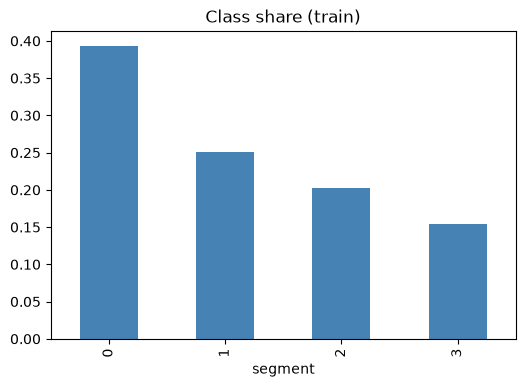

In [4]:
vc = train[TARGET].value_counts(normalize=True).sort_index()
print(vc.round(3))
vc.plot(kind="bar", color="steelblue", figsize=(6, 4), title="Class share (train)")
plt.show()

columns with missing values: 44 | max missing %: 30.8


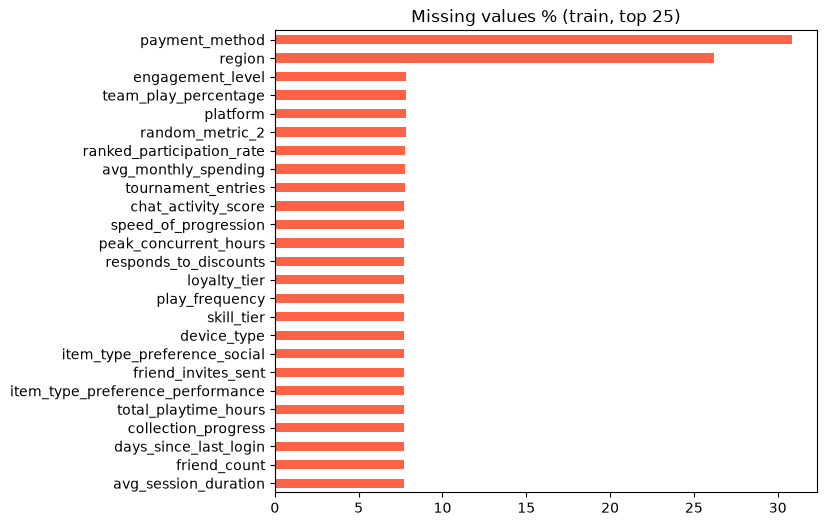

In [5]:
miss = (train.drop(columns=[TARGET]).isna().mean() * 100).sort_values(ascending=False)
print("columns with missing values:", int((miss > 0).sum()), "| max missing %:", round(miss.max(), 1))
miss[miss > 0].head(25).sort_values().plot(kind="barh", color="tomato", figsize=(7, 6),
                                            title="Missing values % (train, top 25)")
plt.show()

most relevant features: ['vip_tier', 'spending_frequency', 'avg_monthly_spending', 'days_since_last_login', 'rare_items_count', 'total_spending_thb', 'total_playtime_hours', 'friend_count', 'friend_invites_sent', 'avg_session_duration']


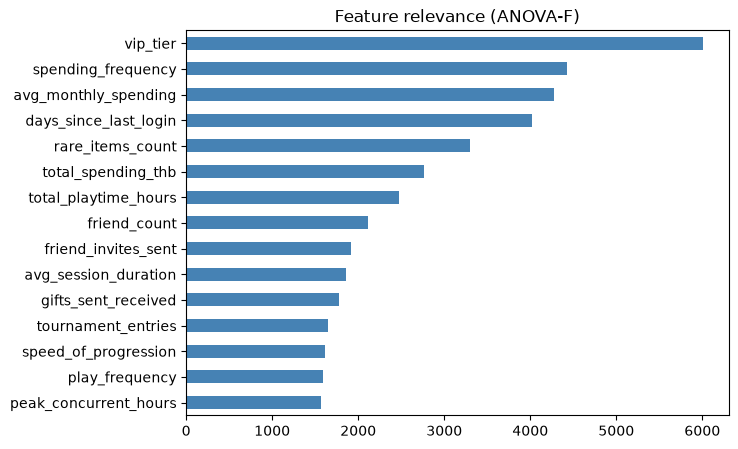

In [6]:
feats = train.drop(columns=["player_id", TARGET])
top = top_features(feats, train[TARGET], KIND)
print("most relevant features:", list(top.index[:10]))
top.sort_values().plot(kind="barh", figsize=(7, 5), color="steelblue", title="Feature relevance (ANOVA-F)")
plt.show()

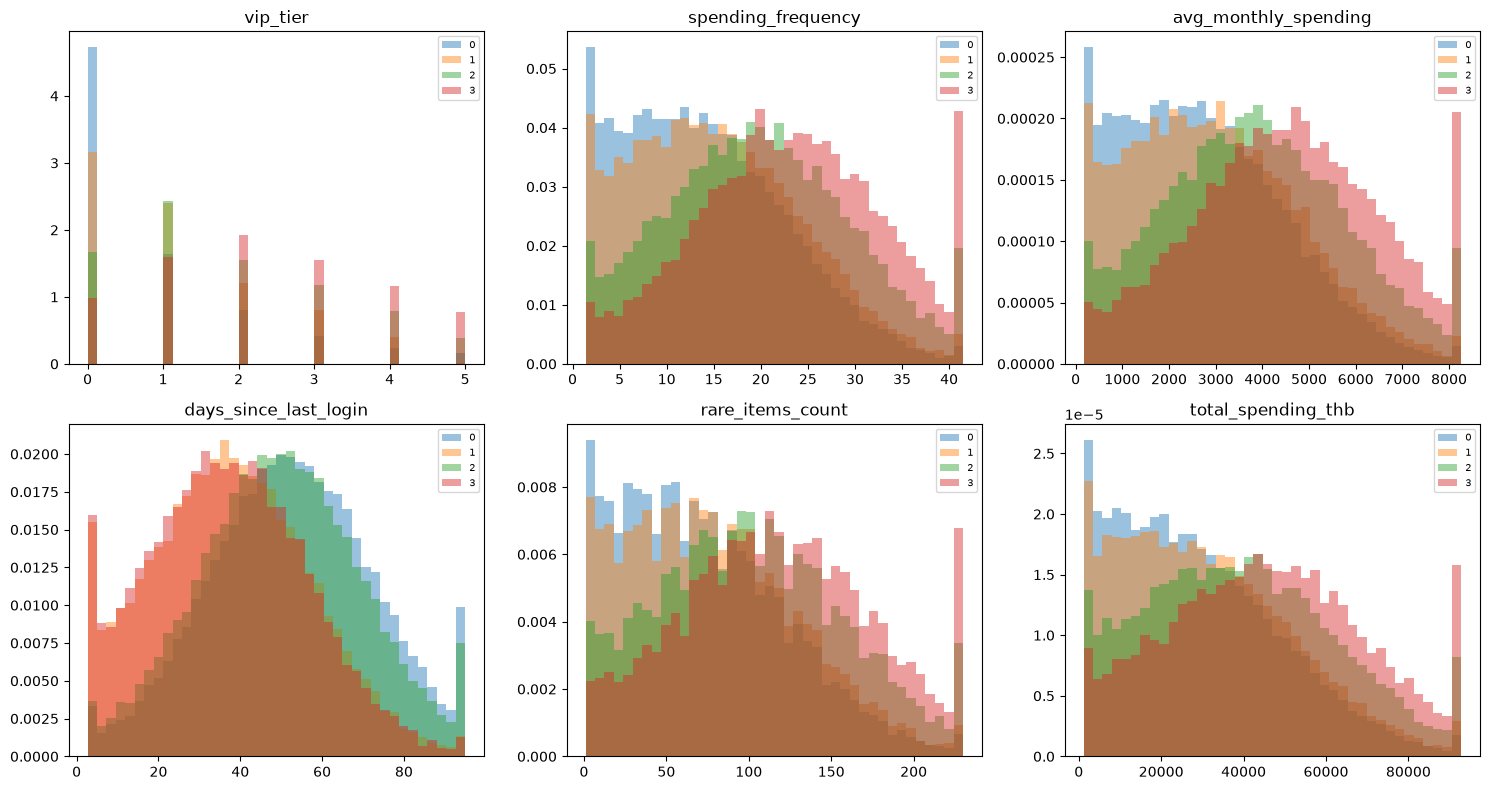

In [7]:
cols = list(top.index[:6])
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.flat, cols):
    lo, hi = train[c].quantile([0.01, 0.99])
    for k in sorted(train[TARGET].dropna().unique()):
        ax.hist(train.loc[train[TARGET] == k, c].dropna().clip(lo, hi), bins=40, alpha=0.45, density=True, label=str(int(k)))
    ax.set_title(c); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

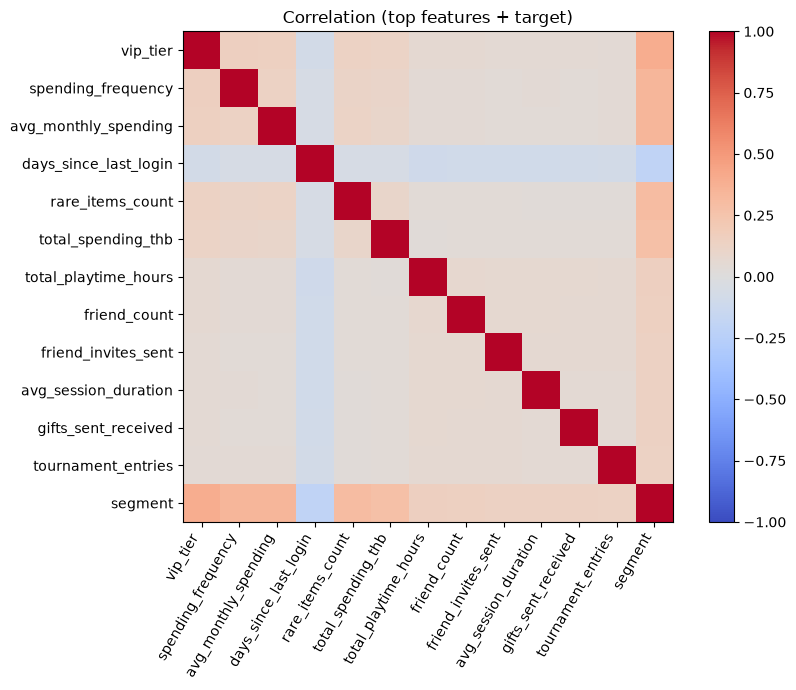

In [8]:
hm = feats[list(top.index[:12])].copy(); hm[TARGET] = train[TARGET]
c = hm.corr()
plt.figure(figsize=(9, 7)); plt.imshow(c, cmap="coolwarm", vmin=-1, vmax=1); plt.colorbar()
plt.xticks(range(len(c)), c.columns, rotation=60, ha="right"); plt.yticks(range(len(c)), c.columns)
plt.title("Correlation (top features + target)"); plt.tight_layout(); plt.show()

## 4. Data Preprocessing

- drop the 3 `random_metric_*` noise columns (the EDA shows they are not among the relevant features)
- winsorise numeric features (bounds from train)
- 10 categorical columns: integer codes for trees, one-hot for LogisticRegression / RandomForest (category lists from **train only**)
- engineered spending / social ratios

In [9]:
y = train[TARGET].astype(int).values
cat = [c for c in train.columns if c not in ("player_id", TARGET) and not pd.api.types.is_numeric_dtype(train[c])]
num = [c for c in train.columns if c not in ["player_id", TARGET, *NOISE, *cat]]
Xn, Xtn = train[num], test[num]
bounds = fit_clip(Xn)
Xn, Xtn = apply_clip(Xn, bounds), apply_clip(Xtn, bounds)

def engineer(X):
    X = X.copy()
    X["spend_per_hour"] = X["total_spending_thb"] / (X["total_playtime_hours"] + 1)
    X["spend_per_day"] = X["total_spending_thb"] / (X["account_age_days"] + 1)
    X["social_ratio"] = X["friend_count"] / (X["total_playtime_hours"] + 1)
    X["cosmetic_minus_perf"] = X["item_type_preference_cosmetic"] - X["item_type_preference_performance"]
    return X

Xn, Xtn = engineer(Xn), engineer(Xtn)
codes_tr, codes_te = {}, {}
for c in cat:
    cats = pd.Categorical(train[c]).categories           # categories from TRAIN only
    codes_tr[c] = pd.Categorical(train[c], categories=cats).codes.astype(float)
    codes_te[c] = pd.Categorical(test[c], categories=cats).codes.astype(float)
codes_tr = pd.DataFrame(codes_tr, index=train.index).replace(-1, np.nan)
codes_te = pd.DataFrame(codes_te, index=test.index).replace(-1, np.nan)
ohe_tr = pd.get_dummies(train[cat], dtype=float)
ohe_te = pd.get_dummies(test[cat], dtype=float).reindex(columns=ohe_tr.columns, fill_value=0.0)

X, Xt = pd.concat([Xn, codes_tr], axis=1), pd.concat([Xtn, codes_te], axis=1)
Xi, Xti, scaler_parts = impute_scale(pd.concat([Xn, ohe_tr], axis=1), pd.concat([Xtn, ohe_te], axis=1))
print(f"tree features: {X.shape[1]} | linear/RF features: {Xi.shape[1]}")

tree features: 45 | linear/RF features: 75


## 5. Model Training & Validation

### 5.1 Compare models on an 80/20 hold-out split (metric: macro-F1)

LogisticRegression       | 0.7496 |     1s


RandomForest             | 0.7246 |    20s


HistGradientBoosting     | 0.7453 |    26s


LightGBM                 | 0.7508 |    36s


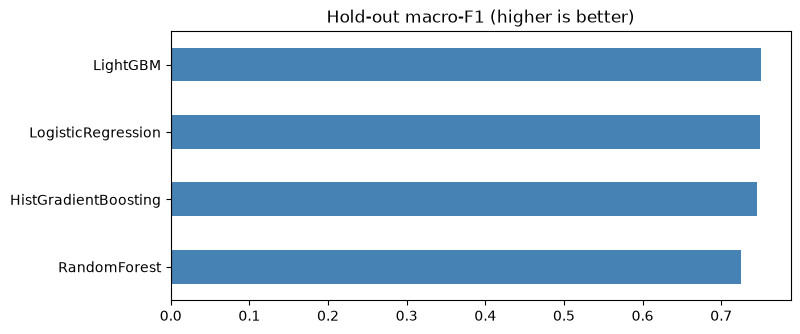

Best model: LightGBM (macro-F1 = 0.7508)


In [10]:
n_tree = 60 if QUICK else 300
models = {
    "LogisticRegression": (lambda: LogisticRegression(max_iter=300, C=0.5), "imp"),
    "RandomForest": (lambda: RandomForestClassifier(n_estimators=n_tree, min_samples_leaf=3, n_jobs=-1, random_state=SEED), "imp"),
    "HistGradientBoosting": (lambda: HistGradientBoostingClassifier(max_iter=n_tree * 2, learning_rate=0.05, early_stopping=True, random_state=SEED), "nan"),
    "LightGBM": (lambda: lgb.LGBMClassifier(n_estimators=300 if QUICK else 4000, learning_rate=0.03, num_leaves=31, min_child_samples=40,
                                            subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=2.0,
                                            random_state=SEED, n_jobs=-1, verbose=-1), "nan"),
}
tr, va = train_test_split(np.arange(len(X)), test_size=0.2, stratify=y, random_state=SEED)
data = {"nan": (X.iloc[tr], X.iloc[va]), "imp": (Xi.iloc[tr], Xi.iloc[va])}
scores = compare_models(models, data, y[tr], y[va], lambda yt, p: f1_score(yt, p.argmax(1), average="macro"), KIND)
res = pd.Series(scores).sort_values()
res.plot(kind="barh", figsize=(8, 3.5), color="steelblue", title="Hold-out macro-F1 (higher is better)")
plt.show()
best = res.idxmax()
print("Best model:", best, f"(macro-F1 = {res.max():.4f})")

### 5.2 Train the best model with 5-fold CV and tune per-class weights on the out-of-fold predictions

fold 1/5 done


fold 2/5 done


fold 3/5 done


fold 4/5 done


fold 5/5 done


OOF macro-F1: argmax = 0.7520 | with tuned class weights = 0.7523 | weights = [0.85 1.   0.95 1.  ]


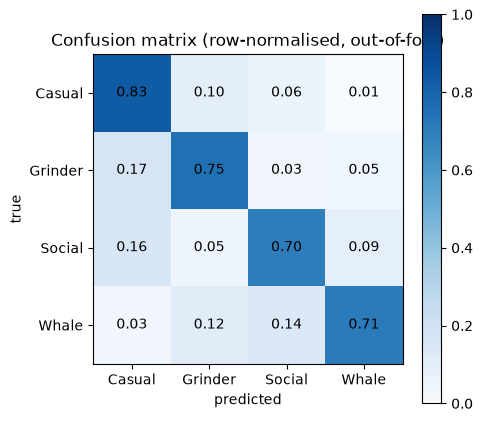

              precision    recall  f1-score   support

      Casual       0.80      0.83      0.82     40957
     Grinder       0.74      0.75      0.74     26032
      Social       0.72      0.70      0.71     21029
       Whale       0.77      0.71      0.74     15982

    accuracy                           0.77    104000
   macro avg       0.76      0.75      0.75    104000
weighted avg       0.76      0.77      0.76    104000



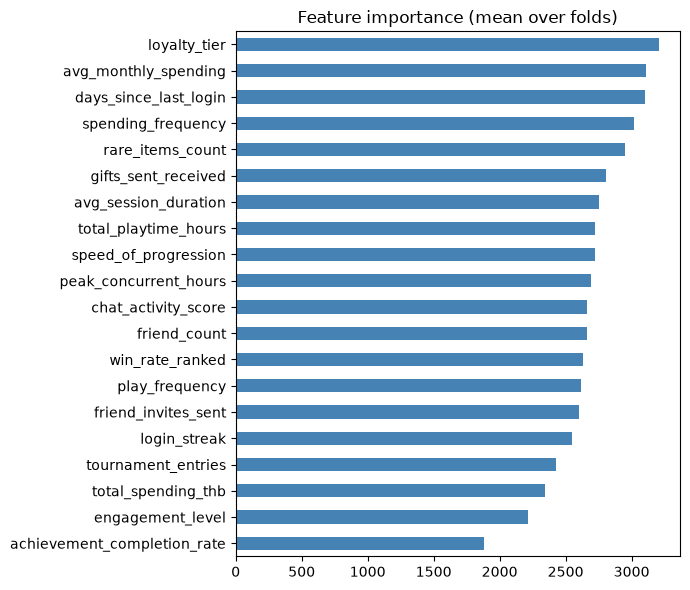

In [11]:
full = {"nan": (X, Xt), "imp": (Xi, Xti)}
oof, pt, fold_models = cv_predict(best, models[best], full, y,
                                  StratifiedKFold(3 if QUICK else 5, shuffle=True, random_state=SEED), KIND)

def tune_weights(y, proba, rounds=3):
    w = np.ones(proba.shape[1]); grid = np.arange(0.5, 2.51, 0.05)
    best_s = f1_score(y, (proba * w).argmax(1), average="macro")
    for _ in range(rounds):
        for k in range(len(w)):
            for g in grid:
                w2 = w.copy(); w2[k] = g
                s = f1_score(y, (proba * w2).argmax(1), average="macro")
                if s > best_s + 1e-6:
                    best_s, w = s, w2
    return w, best_s

base = f1_score(y, oof.argmax(1), average="macro")
w, tuned = tune_weights(y, oof)
print(f"OOF macro-F1: argmax = {base:.4f} | with tuned class weights = {tuned:.4f} | weights = {np.round(w, 2)}")
confusion_plot(y, (oof * w).argmax(1), NAMES)
print(classification_report(y, (oof * w).argmax(1), target_names=NAMES))
feature_importance_plot(fold_models, X.columns)

## 6. Predict on the Test Set & Save

         train  test predicted
Casual   0.394           0.408
Grinder  0.250           0.258
Social   0.202           0.195
Whale    0.154           0.140


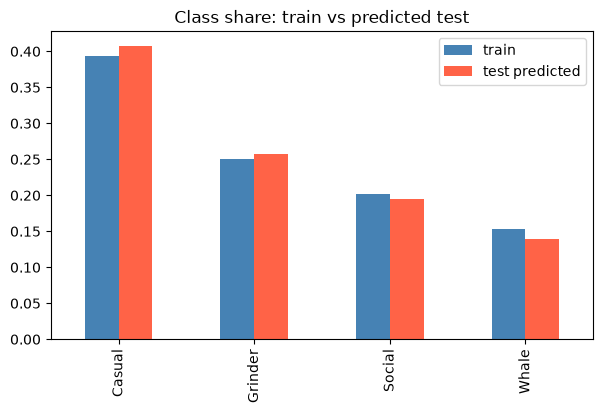

saved 25889 predictions -> D:\CPE3TERM1\CPE342 ML\Lab\cpe342-kaggle-main\outputs\task2_pred.csv
saved model -> D:\CPE3TERM1\CPE342 ML\Lab\cpe342-kaggle-main\outputs\models\task2_model.joblib


In [12]:
pred = (pt * w).argmax(1)
share = pd.DataFrame({"train": pd.Series(y).value_counts(normalize=True).sort_index(),
                      "test predicted": pd.Series(pred).value_counts(normalize=True).sort_index()}).set_axis(NAMES)
print(share.round(3))
share.plot(kind="bar", figsize=(7, 4), color=["steelblue", "tomato"], title="Class share: train vs predicted test")
plt.show()
save_outputs(TASK, pred, {"name": best, "fold_models": fold_models, "class_weights": w, "clip_bounds": bounds,
                          "imputer_scaler": scaler_parts, "features": list(X.columns), "classes": NAMES},
             {f"p{k}": pt[:, k] for k in range(4)})